# MGH Data Case Study
### This file written by @Zack-Boner

## Description of data

The dataset used in this case study was provided by the Massachussetts General Hospital, by a team led by Dr. Brandon Westover.
The data consists of 12 features typically used to compute the Sequential Organ Failure Assessment (SOFA) score, which is used to determine the level of acuity and mortality risk for patients admitted to the intensive care unit.
An online calculator for the SOFA score may be found at the following link: [https://www.mdcalc.com/calc/691/sequential-organ-failure-assessment-sofa-score#next-steps].

The label describes whether the patient died during their stay in the ICU.

In [1]:
SOFA_FEATURES = [
    'Total_Bilirubin_mg_per_dL', 'MAP', 'Creatinine_mg_per_dL', 'Dobutamine_any_dose', 'Dopamine_μg_kg_min',
    'Epinephrine_μg_kg_min', 'GCS', 'mech_vent_cpap', 'Norepinephrine_μg_kg_min', 'PaO2_FiO2', 'Platelets_10_3_per_ml',
    'Urine_output_mL'
]
label = 'died_in_ICU'

### Imports for data section

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from data.MGH.processing.calc_sofa import calc_sofa

### EDA

In [3]:
df = pd.read_csv('data/MGH/processed_data/full_patient_df.csv')
X = df[SOFA_FEATURES]
y = df[label]
sofa_scores = X.fillna(0).apply(calc_sofa, axis=1)

df.head(5)

,Admission,SexDSC,PatientRaceDSC,EthnicGroupDSC,Age,Hours_to_mortality,Days_to_mortality,Months_to_mortality,Years_to_mortality,Time_to_death,...,Epinephrine_μg_kg_min,GCS,mech_vent_cpap,Norepinephrine_μg_kg_min,PaO2,FiO2,PaO2_FiO2,Platelets_10_3_per_ml,Urine_output_mL,died_in_ICU
0,0,Male,White,Not Hispanic,79,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,1.0,0.0,71.0,0.4,142.0,503.0,NaN,False
1,1,Male,White,Not Hispanic,63,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,1.0,10.5,125.0,0.4,208.0,155.0,1080.0,False
2,2,Female,White,Not Hispanic,75,8.0,0.0,9.0,3.0,1370 days 08:14:00,...,0.0,NaN,0.0,0.0,90.0,0.3,300.0,252.0,NaN,False
3,3,Female,White,Not Hispanic,78,8.0,20.0,0.0,0.0,20 days 08:53:00,...,0.0,12.0,0.0,0.0,NaN,NaN,NaN,207.0,1466.0,True
4,4,Male,White,Not Hispanic,21,NaN,NaN,NaN,NaN,NaN,...,0.0,NaN,0.0,37.5,NaN,NaN,NaN,358.0,1185.0,False


In [4]:
X.describe()

,Total_Bilirubin_mg_per_dL,MAP,Creatinine_mg_per_dL,Dobutamine_any_dose,Dopamine_μg_kg_min,Epinephrine_μg_kg_min,GCS,mech_vent_cpap,Norepinephrine_μg_kg_min,PaO2_FiO2,Platelets_10_3_per_ml,Urine_output_mL
count,3739.000000,4810.000000,4938.000000,5000.000000,5000.000000,5000.000000,2643.000000,5000.000000,5000.000000,1457.000000,4947.000000,4561.000000
mean,1.328270,72.043105,1.552305,0.009400,0.582040,1.140000,11.542565,0.327200,18.644080,243.602408,189.749343,1451.877001
std,3.204395,14.869244,1.625352,0.096506,6.391701,13.864986,4.236032,0.469238,343.667342,123.954884,95.859128,1190.516262
min,0.100000,20.000000,0.170000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,30.000000,0.000000,0.000000
25%,0.400000,62.333333,0.820000,0.000000,0.000000,0.000000,8.000000,0.000000,0.000000,143.000000,127.000000,625.000000
50%,0.600000,71.000000,1.060000,0.000000,0.000000,0.000000,14.000000,0.000000,0.000000,231.000000,179.000000,1200.000000
75%,1.000000,81.000000,1.580000,0.000000,0.000000,0.000000,15.000000,1.000000,0.000000,322.000000,235.000000,2005.000000
max,64.000000,142.333333,34.230000,1.000000,170.100000,540.000000,15.000000,1.000000,17250.000000,819.047619,1294.000000,13750.000000


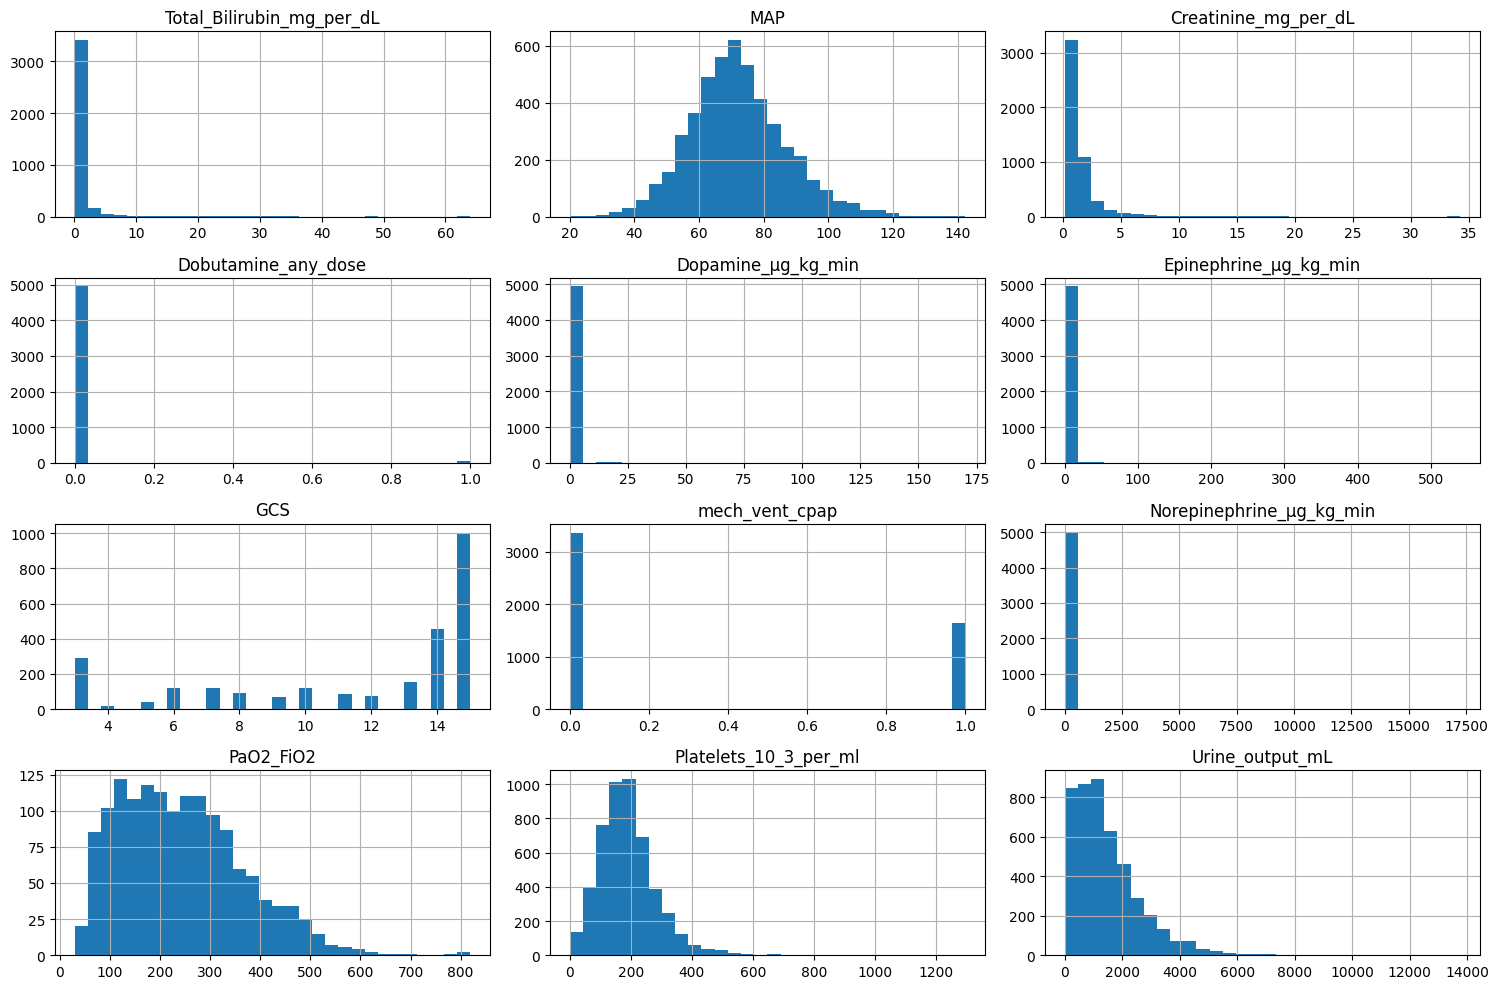

In [5]:
# plot histogram of each feature in SOFA_FEATURES
X.hist(bins=30, figsize=(15, 10))
plt.tight_layout()
plt.show()

<Axes: >

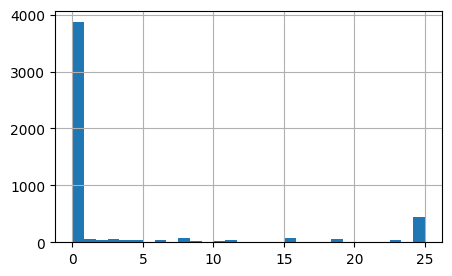

In [9]:
X['Norepinephrine_μg_kg_min'].clip(upper=25).hist(bins=30, figsize=(5, 3))

In [6]:
y.describe()

count      5000
unique        2
top       False
freq       4351
Name: died_in_ICU, dtype: object

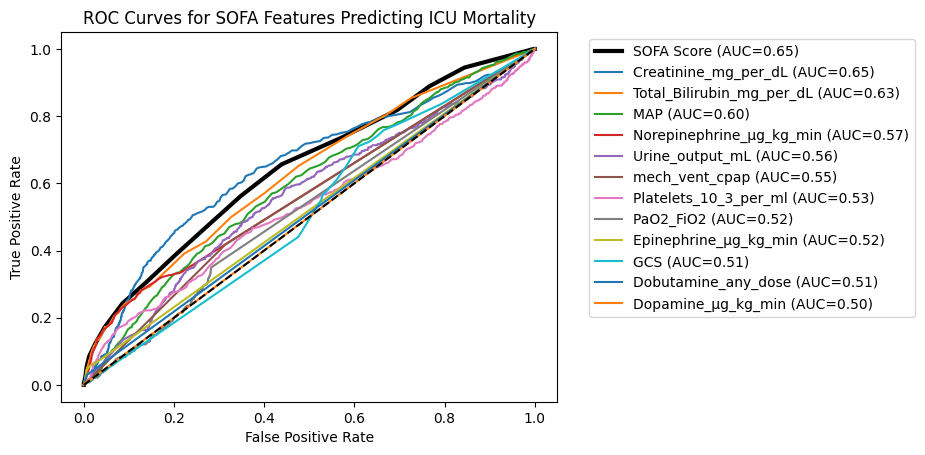

In [7]:
feature_ROCs = {
    feature: (roc_curve(y, X[feature].fillna(0.)), roc_auc_score(y, X[feature].fillna(0.))) for feature in SOFA_FEATURES
}
# correct for AUC < 0.5 by inverting the ROC curve
for feature, (roc_data, auc) in feature_ROCs.items():
    if auc < 0.5:
        fpr, tpr, thresholds = roc_data
        fpr, tpr = 1 - fpr, 1 - tpr
        feature_ROCs[feature] = ( (fpr, tpr, thresholds), 1 - auc )
        
sofa_roc = roc_curve(y, sofa_scores)
sofa_auc = roc_auc_score(y, sofa_scores)
plt.plot(sofa_roc[0], sofa_roc[1], label=f'SOFA Score (AUC={sofa_auc:.2f})', color='black', linewidth=3)

for feature, (roc_data, auc) in sorted(feature_ROCs.items(), key=lambda item: item[1][1], reverse=True):
    fpr, tpr, thresholds = roc_data
    plt.plot(fpr, tpr, label=f'{feature} (AUC={auc:.2f})')
    
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for SOFA Features Predicting ICU Mortality')
# put legend outside of plot
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## Modeling

### Imports for modeling section

In [64]:
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score, confusion_matrix, precision_score, recall_score, precision_recall_curve
from pystreed import STreeDClassifier
from pycontree import ConTree
from interpret.glassbox import ExplainableBoostingClassifier

from falling_trees.frl_rashomon_set_alg import OptFallingTree, print_tree
from experiments.utils import predict_proba_falling_tree, predict_falling_tree

## 

### Baselines

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
baseline_models = {
    'Logistic Regression': {
        'model': LogisticRegression(class_weight='balanced', max_iter=1000),
        'imputer': 'median',
        'scaler': StandardScaler(),
    },
    'CatBoost': {
        'model': CatBoostClassifier(verbose=0, auto_class_weights='Balanced'),
        'imputer': None,
    },
    'EBM': {
        'model': ExplainableBoostingClassifier(random_state=42, missing='low'),
        'imputer': None,
    },
    'STreeD': {
        'model': STreeDClassifier(optimization_task='f1-score', hyper_tune=True),
        'imputer': 'low_extreme',
    },
}

In [29]:
def evaluate_model(fit_model, X_test, y_test):
    y_pred = fit_model.predict(X_test)
    y_pred_proba = fit_model.predict_proba(X_test)
    if len(y_pred_proba.shape) > 1 and y_pred_proba.shape[1] > 1:
        y_pred_proba = fit_model.predict_proba(X_test)[:, 1]
    else:
        y_pred_proba = fit_model.predict_proba(X_test)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba)
    cm = confusion_matrix(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    return f1, auc, cm, precision, recall

In [12]:
for name, model_info in baseline_models.items():
    model = model_info['model']
    
    if 'scaler' in model_info and model_info['scaler'] is not None:
        scaler = model_info['scaler']
        X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
        X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
    else:
        X_train_scaled = X_train.copy()
        X_test_scaled = X_test.copy()
    
    fillna_strategy = model_info['imputer']
    
    X_train_filled = X_train_scaled.copy()
    X_test_filled = X_test_scaled.copy()
    
    if fillna_strategy == 'median':
        X_train_filled = X_train_filled.fillna(X_train_filled.median())
        X_test_filled = X_test_filled.fillna(X_train_filled.median())
    elif fillna_strategy == 'low_extreme':
        for col in X_train_filled.columns:
            low_value = -1
            X_train_filled[col] = X_train_filled[col].fillna(low_value)
            X_test_filled[col] = X_test_filled[col].fillna(low_value)
    
    model.fit(X_train_filled, y_train)
    f1, auc, confusion, precision, recall = evaluate_model(model, X_test_filled, y_test)
    
    print(f'{name} F1 Score: {f1:.4f}')
    print(f'{name} Precision: {precision:.4f}')
    print(f'{name} Recall: {recall:.4f}')
    print(f'{name} AUC: {auc:.4f}')
    print(f'{name} Confusion Matrix:\n{confusion}\n')
    print()

Logistic Regression F1 Score: 0.3307
Logistic Regression Precision: 0.2302
Logistic Regression Recall: 0.5872
Logistic Regression AUC: 0.7168
Logistic Regression Confusion Matrix:
[[677 214]
 [ 45  64]]


CatBoost F1 Score: 0.3257
CatBoost Precision: 0.2525
CatBoost Recall: 0.4587
CatBoost AUC: 0.7316
CatBoost Confusion Matrix:
[[743 148]
 [ 59  50]]




/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/interpret/glassbox/_ebm/_ebm.py:871: UserWarning: Missing values detected. Our visualizations do not currently display missing values. To retain the glassbox nature of the model you need to either set the missing values to an extreme value like -1000 that will be visible on the graphs, or manually examine the missing value score in ebm.term_scores_[term_index][0]
  warn(


EBM F1 Score: 0.1231
EBM Precision: 0.3810
EBM Recall: 0.0734
EBM AUC: 0.7465
EBM Confusion Matrix:
[[878  13]
 [101   8]]


STreeD F1 Score: 0.2828
STreeD Precision: 0.1951
STreeD Recall: 0.5138
STreeD AUC: 0.6590
STreeD Confusion Matrix:
[[660 231]
 [ 53  56]]




In [13]:
ebm = baseline_models['EBM']['model']
ebm_preds = ebm.predict_proba(X_test.fillna(0))[:, 1]
# find best threshold based on f1 score
best_f1 = 0
best_thresh = 0
for thresh in np.arange(0, 1, 0.01):
    ebm_binary_preds = (ebm_preds >= thresh).astype(int)
    f1 = f1_score(y_test, ebm_binary_preds)
    if f1 > best_f1:
        best_f1 = f1
        best_thresh = thresh
print(f'EBM Best Threshold for F1: {best_thresh:.2f} with F1 Score: {best_f1:.4f}')

EBM Best Threshold for F1: 0.26 with F1 Score: 0.3581


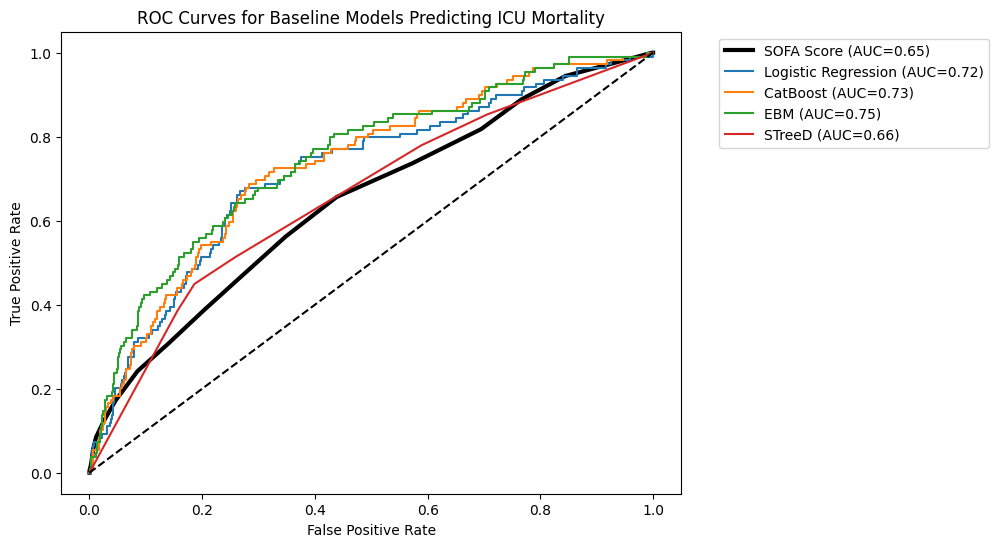

In [14]:
# plot ROC curves
plt.figure(figsize=(8, 6))

plt.plot(sofa_roc[0], sofa_roc[1], label=f'SOFA Score (AUC={sofa_auc:.2f})', color='black', linewidth=3)

for name, model_info in baseline_models.items():
    model = model_info['model']
    if 'scaler' in model_info and model_info['scaler'] is not None:
        scaler = model_info['scaler']
        X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
        X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
    else:
        X_train_scaled = X_train.copy()
        X_test_scaled = X_test.copy()
    
    fillna_strategy = model_info['imputer']
    X_test_filled = X_test_scaled.copy()
    
    if fillna_strategy == 'median':
        X_test_filled = X_test_filled.fillna(X_train_scaled.median())
    elif fillna_strategy == 'low_extreme':
        for col in X_test_filled.columns:
            low_value = -1
            X_test_filled[col] = X_test_filled[col].fillna(low_value)
    
    y_pred_proba = model.predict_proba(X_test_filled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    auc = roc_auc_score(y_test, y_pred_proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.2f})')   
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves for Baseline Models Predicting ICU Mortality')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

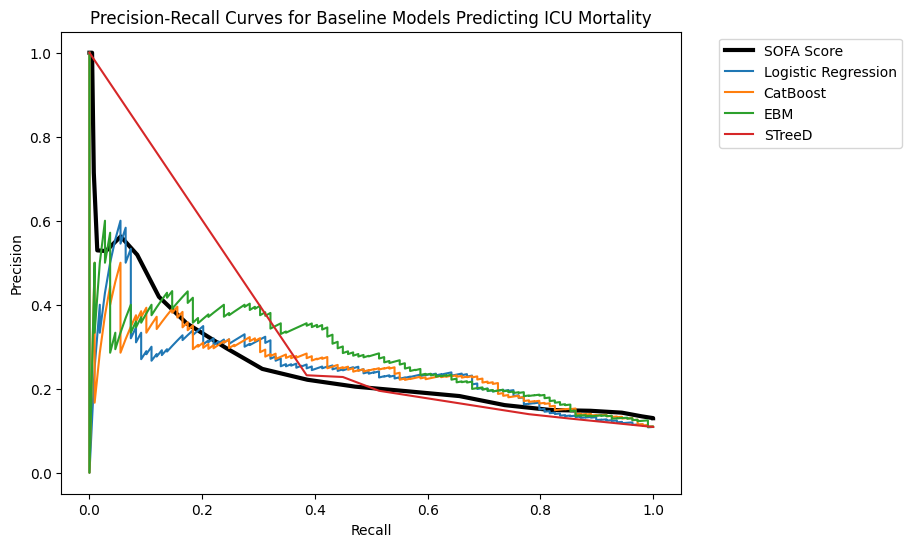

In [15]:
# plot precision-recall curves
plt.figure(figsize=(8, 6))

sofa_precision, sofa_recall, _ = precision_recall_curve(y, sofa_scores)
plt.plot(sofa_recall, sofa_precision, label=f'SOFA Score', color='black', linewidth=3)

for name, model_info in baseline_models.items():
    model = model_info['model']
    if 'scaler' in model_info and model_info['scaler'] is not None:
        scaler = model_info['scaler']
        X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
        X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)
    else:
        X_train_scaled = X_train.copy()
        X_test_scaled = X_test.copy()
    
    fillna_strategy = model_info['imputer']
    X_test_filled = X_test_scaled.copy()
    
    if fillna_strategy == 'median':
        X_test_filled = X_test_filled.fillna(X_train_scaled.median())
    elif fillna_strategy == 'low_extreme':
        for col in X_test_filled.columns:
            low_value = -1
            X_test_filled[col] = X_test_filled[col].fillna(low_value)
    
    y_pred_proba = model.predict_proba(X_test_filled)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
    plt.plot(recall, precision, label=f'{name}')   
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curves for Baseline Models Predicting ICU Mortality')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

### FRAME

In [85]:
from frame.FRL import FallingRuleList
from falling_trees.binarize_dataset import binarize_dataset, cut


X_train_fillna = X_train.fillna(-1)
train_df = X_train_fillna.copy()
train_df[label] = y_train.astype(int)
df_fillna_binary, thresholds, header, threshold_guess_time = binarize_dataset(train_df, 100)
X_train_fillna_binary = df_fillna_binary[header]
y_train_ = df_fillna_binary[label]
X_test_fillna = X_test.fillna(-1)
X_test_fillna_binary = cut(X_test_fillna, thresholds)[header]

frl = FallingRuleList(w=5.5, C=0.005)
frl.fit(X_train_fillna_binary.astype(bool), y_train_, opt_curiosity='ucb', include_complement=True, verbose=False)
for col in X_test_fillna_binary.columns:
    X_test_fillna_binary['~' + col] = 1 - X_test_fillna_binary[col]
f1, auc, confusion, precision, recall = evaluate_model(frl, X_test_fillna_binary.astype(bool), y_test)
print(f'FRL F1 Score: {f1:.4f}')
print(f'FRL Precision: {precision:.4f}')
print(f'FRL Recall: {recall:.4f}')
print(f'FRL AUC: {auc:.4f}')
print(f'FRL Confusion Matrix:\n{confusion}\n')

/home/users/zwb3/research/falling-models/.venv/lib/python3.13/site-packages/mlxtend/frequent_patterns/fpcommon.py:161: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


FRL F1 Score: 0.2685
FRL Precision: 0.1796
FRL Recall: 0.5321
FRL AUC: 0.6314
FRL Confusion Matrix:
[[626 265]
 [ 51  58]]



In [55]:
print(frl)

                                                                                                   Rule Probability   +    -
     if                   ~Total_Bilirubin_mg_per_dL<=0.45000000298023224 & Platelets_10_3_per_ml<=52.5       0.359  52   93
else if            ~Creatinine_mg_per_dL<=1.9450000524520874 & ~Creatinine_mg_per_dL<=1.034999966621399       0.280 178  458
else if ~Norepinephrine_μg_kg_min<=25.149999618530273 & ~Total_Bilirubin_mg_per_dL<=0.15000000223517418       0.261  43  122
else if                                                             ~Urine_output_mL<=3295.0 & GCS<=9.5       0.227  27   92
else if                    Platelets_10_3_per_ml<=219.5 & ~Total_Bilirubin_mg_per_dL<=2.350000023841858       0.157  13   70
else if                       Norepinephrine_μg_kg_min<=8.650000095367432 & Platelets_10_3_per_ml<=49.5       0.156   7   38
   else                                                                                                       0.078 220 2587


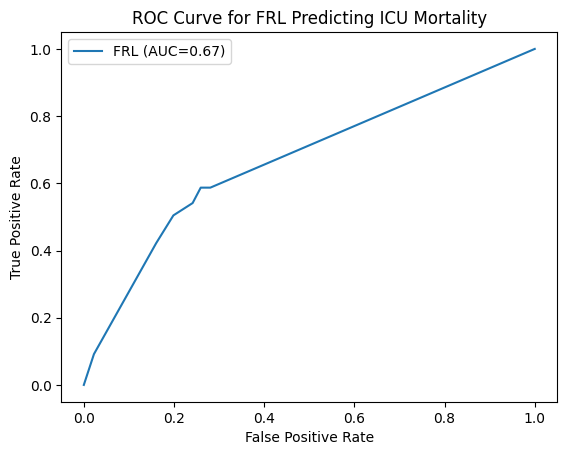

In [57]:
y_pred_proba = frl.predict_proba(X_test_fillna_binary.astype(bool))
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)

plt.plot(fpr, tpr, label=f'FRL (AUC={auc:.2f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for FRL Predicting ICU Mortality')
plt.legend()
plt.show()

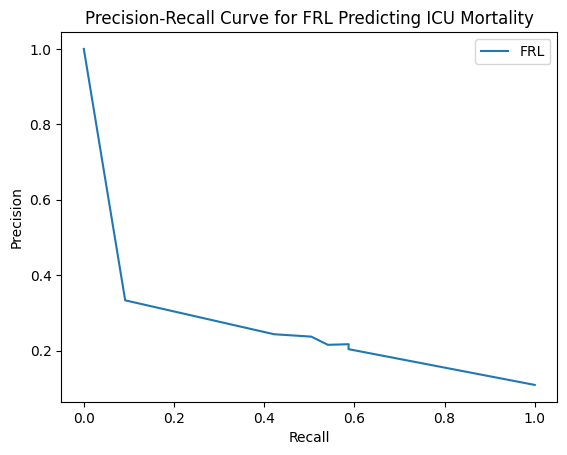

In [58]:
precisions, recalls, _ = precision_recall_curve(y_test, y_pred_proba)
plt.plot(recalls, precisions, label='FRL')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for FRL Predicting ICU Mortality')
plt.legend()
plt.show()

### Falling Trees

In [92]:
X_train_fillna = X_train.fillna(-1)
train_df = X_train_fillna.copy()
train_df[label] = y_train.astype(int)
df_fillna_binary, thresholds, header, threshold_guess_time = binarize_dataset(train_df, 50)
X_train_fillna_binary = df_fillna_binary[header]
y_train_ = df_fillna_binary[label]
X_test_fillna = X_test.fillna(-1)
X_test_fillna_binary = cut(X_test_fillna, thresholds)[header]

X_train_balanced = X_train_fillna_binary.loc[y_train_==1]
X_train_balanced = pd.concat([X_train_balanced, X_train_fillna_binary[y_train_ == 0].sample(n=X_train_balanced.shape[0], random_state=42)])
y_train_balanced = pd.Series([1] * (X_train_balanced.shape[0] // 2) + [0] * (X_train_balanced.shape[0] // 2))

features = list(range(X_train_balanced.shape[1]))
print(len(features))
depth = 5  # Reasonable depth for this dataset
enable_falling_constraint = True
use_heap = True  # Use heap for storing trees in Rashomon set
rule_list_mode_for_optimal = False
MAX_CACHE_SIZE = 100000  # Default value, can be adjusted
kwargs = {"branching_cost": 0.01, "min_support": 0.01}
n = X_train_balanced.shape[0]
row_idx = np.arange(n)

best_loss, best_tree, pmax, depth_of_pmax = OptFallingTree(X_train_balanced.values,
                                                            y_train_balanced.astype(int).values,
                                                            row_idx,
                                                            depth,
                                                            0,
                                                            features,
                                                            n=n,
                                                            enable_falling_constraint=enable_falling_constraint,
                                                            rule_list_mode=rule_list_mode_for_optimal,
                                                            **kwargs)
print_tree(best_tree)

24
Node(feature=17)
  Leaf(pred_prob=0.765, objective=0.025)
  Node(feature=8)
    Node(feature=0)
      Leaf(pred_prob=0.708, objective=0.068)
      Node(feature=14)
        Leaf(pred_prob=0.700, objective=0.014)
        Node(feature=10)
          Leaf(pred_prob=0.522, objective=0.030)
          Leaf(pred_prob=0.304, objective=0.019)
    Node(feature=3)
      Leaf(pred_prob=0.750, objective=0.003)
      Node(feature=22)
        Leaf(pred_prob=0.714, objective=0.004)
        Node(feature=20)
          Leaf(pred_prob=0.309, objective=0.136)
          Leaf(pred_prob=0.667, objective=0.008)


In [96]:
y_pred_proba = predict_proba_falling_tree(best_tree, X_test_fillna_binary.values)
f1 = f1_score(y_test, (y_pred_proba >= 0.5).astype(int))
precision = precision_score(y_test, (y_pred_proba >= 0.5).astype(int))
recall = recall_score(y_test, (y_pred_proba >= 0.5).astype(int))
auc = roc_auc_score(y_test, y_pred_proba)
confusion = confusion_matrix(y_test, (y_pred_proba >= 0.5).astype(int))
print(f'Falling Tree F1 Score: {f1:.4f}')
print(f'Falling Tree Precision: {precision:.4f}')
print(f'Falling Tree Recall: {recall:.4f}') 
print(f'Falling Tree AUC: {auc:.4f}')
print(f'Falling Tree Confusion Matrix:\n{confusion}\n')

Falling Tree F1 Score: 0.2934
Falling Tree Precision: 0.1893
Falling Tree Recall: 0.6514
Falling Tree AUC: 0.6776
Falling Tree Confusion Matrix:
[[587 304]
 [ 38  71]]



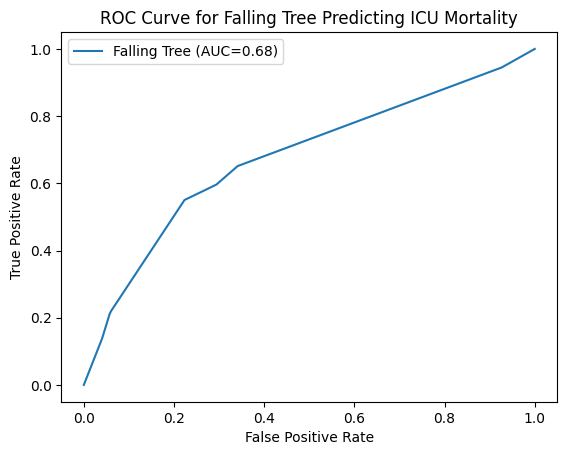

In [94]:
roc_curves = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)
plt.plot(roc_curves[0], roc_curves[1], label=f'Falling Tree (AUC={auc:.2f})')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Falling Tree Predicting ICU Mortality')
plt.legend()
plt.show()

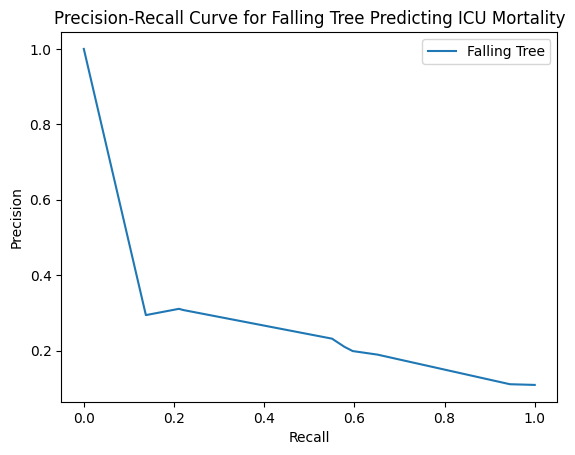

In [95]:
precisions, recalls, _ = precision_recall_curve(y_test, y_pred_proba)
plt.plot(recalls, precisions, label='Falling Tree')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve for Falling Tree Predicting ICU Mortality')
plt.legend()
plt.show()